# Практические задания 2.1–2.10

**Системы поддержки принятия решений · ЛЭТИ**  
**Студент:** Боронин Дмитрий Денисович

Источник постановок: методическое пособие, с. 93–97; приём линеаризации модулей — с. 62–63.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pyomo.environ as pyo
from IPython.display import display
from pyomo.opt import TerminationCondition

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 110)

def solve(model):
    """Решить модель и остановить выполнение при отсутствии оптимума."""
    solver = pyo.SolverFactory("appsi_highs")
    if not solver.available():
        raise RuntimeError("Нужны pyomo и highspy: pip install -r requirements.txt")
    result = solver.solve(model)
    if result.solver.termination_condition != TerminationCondition.optimal:
        raise RuntimeError(f"HiGHS: {result.solver.termination_condition}")
    return model

print("Pyomo и HiGHS готовы к расчёту.")

Pyomo и HiGHS готовы к расчёту.


## Задача 2.1. Комплекты смартфонов и двойственные оценки

**Условие.** В наличии 8 телефонов, 4 гарнитуры и 19 карт. Комплект 1 содержит телефон и две карты, прибыль — 7 долл.; комплект 2 — телефон, гарнитуру и три карты, прибыль — 9 долл. Нужно выбрать объёмы комплектов, определить оценки отдельных товаров и сравнить предложения 65, 62 и 60 долл. за весь запас.

**Математическая модель.** $x_1,x_2\ge0$ — числа комплектов. Прямая и двойственная задачи:

$$\begin{aligned}
\max\;&7x_1+9x_2\\
x_1+x_2&\le8 &&\text{телефоны},\\
x_2&\le4 &&\text{гарнитуры},\\
2x_1+3x_2&\le19 &&\text{карты};
\end{aligned}\qquad
\begin{aligned}
\min\;&8u+4v+19w\\
u+2w&\ge7,\\
u+v+3w&\ge9,\\
u,v,w&\ge0.
\end{aligned}$$

$u,v,w$ — предельная ценность ещё одной единицы соответствующего запаса при неизменном оптимальном базисе.

In [2]:
m21 = pyo.ConcreteModel()
m21.x1 = pyo.Var(domain=pyo.NonNegativeReals)
m21.x2 = pyo.Var(domain=pyo.NonNegativeReals)
m21.profit = pyo.Objective(expr=7 * m21.x1 + 9 * m21.x2, sense=pyo.maximize)
m21.phone = pyo.Constraint(expr=m21.x1 + m21.x2 <= 8)
m21.headset = pyo.Constraint(expr=m21.x2 <= 4)
m21.card = pyo.Constraint(expr=2 * m21.x1 + 3 * m21.x2 <= 19)

# Суффикс загружает двойственные оценки ограничений после решения LP.
m21.dual = pyo.Suffix(direction=pyo.Suffix.IMPORT)
solve(m21)
shadow = {
    "Телефон": m21.dual[m21.phone],
    "Гарнитура": m21.dual[m21.headset],
    "Карта": m21.dual[m21.card],
}
print(pd.DataFrame({
    "Комплект": ["Телефон + 2 карты", "Телефон + гарнитура + 3 карты"],
    "Количество": [pyo.value(m21.x1), pyo.value(m21.x2)],
}).round(3).to_string(index=False))
print(f"Максимальная прибыль: ${pyo.value(m21.profit):.2f}")
print(pd.DataFrame.from_dict(shadow, orient="index", columns=["Оценка, $/шт."])
      .round(3).to_string())
for offer in [65, 62, 60]:
    decision = "принять" if offer > pyo.value(m21.profit) else (
        "безразлично" if offer == pyo.value(m21.profit) else "отклонить"
    )
    print(f"Предложение ${offer}: {decision}")

                     Комплект  Количество
            Телефон + 2 карты         5.0
Телефон + гарнитура + 3 карты         3.0
Максимальная прибыль: $62.00
           Оценка, $/шт.
Телефон              3.0
Гарнитура            0.0
Карта                2.0
Предложение $65: принять
Предложение $62: безразлично
Предложение $60: отклонить


- **(a)** $x_1=5$, $x_2=3$; прибыль — 62 долл., остаётся одна гарнитура.
- **(b)** Один оптимальный вектор теневых цен: телефон — 3 долл., гарнитура — 0 долл., карта — 2 долл. Он покрывает прибыль каждого комплекта: $3+2\cdot2=7$ и $3+0+3\cdot2=9$; оценка всего запаса равна $8\cdot3+4\cdot0+19\cdot2=62$. Это согласованный набор цен, а не независимые минимумы каждой позиции.
- **(c)** Задача о ценах двойственна задаче о комплектах; равенство оптимальных значений следует из сильной двойственности.
- **(d)** Предложение 65 долл. выгоднее самостоятельной продажи; 62 долл. эквивалентно; 60 долл. хуже на 2 долл.

## Задача 2.2. Furnco: незавершённая и готовая мебель

**Условие.** До 40 000 досковых футов древесины по 1 долл. за фут и 6000 часов труда. На стол расходуется 15 футов древесины, на стул — 5 футов (уточнение преподавателя). Незавершённый стол или стул требует 2 ч; отделка стола добавляет 3 ч, стула — 2 ч. Выручка от стола без отделки и готового стола — 70 и 140 долл.; от стула — 60 и 110 долл.

**Математическая модель.** $T_u,T_f,C_u,C_f\ge0$ — количества незавершённых и готовых столов/стульев. Готовая вещь учитывается только в готовой категории.

$$\begin{aligned}
\max\;&55T_u+125T_f+55C_u+105C_f\\
15(T_u+T_f)+5(C_u+C_f)&\le40000,\\
2T_u+5T_f+2C_u+4C_f&\le6000.
\end{aligned}$$

Из выручки вычтена стоимость древесины: 15 долл. на стол и 5 долл. на стул. Коэффициенты труда для готовых изделий включают изготовление и отделку.

In [3]:
furnco_items = (
    "Стол без отделки", "Стол готовый",
    "Стул без отделки", "Стул готовый",
)
furnco_revenue = dict(zip(furnco_items, (70, 140, 60, 110)))
furnco_wood = dict(zip(furnco_items, (15, 15, 5, 5)))
furnco_labor = dict(zip(furnco_items, (2, 5, 2, 4)))

unit_economics = pd.DataFrame({
    "Изделие": furnco_items,
    "Выручка, $": [furnco_revenue[k] for k in furnco_items],
    "Древесина, фут": [furnco_wood[k] for k in furnco_items],
    "Труд, ч": [furnco_labor[k] for k in furnco_items],
}).set_index("Изделие")
# Цена древесины — 1 доллар за фут.
unit_economics["Прибыль, $"] = (
    unit_economics["Выручка, $"] - unit_economics["Древесина, фут"]
)
unit_economics["Прибыль на час, $/ч"] = (
    unit_economics["Прибыль, $"] / unit_economics["Труд, ч"]
)
print("Экономика единицы изделия")
display(unit_economics.round(2))

def furnco_model():
    """Построить задачу Furnco с уточнёнными нормами древесины."""
    model = pyo.ConcreteModel()
    model.kind = pyo.Set(initialize=furnco_items, ordered=True)
    model.qty = pyo.Var(model.kind, domain=pyo.NonNegativeReals)
    # Древесина оплачивается даже для изделия без отделки.
    model.profit = pyo.Objective(
        expr=sum((furnco_revenue[k] - furnco_wood[k]) * model.qty[k]
                 for k in model.kind),
        sense=pyo.maximize,
    )
    model.wood = pyo.Constraint(
        expr=sum(furnco_wood[k] * model.qty[k]
                 for k in model.kind) <= 40_000
    )
    model.labor = pyo.Constraint(
        expr=sum(furnco_labor[k] * model.qty[k]
                 for k in model.kind) <= 6_000
    )
    return model

m22 = solve(furnco_model())
furnco_plan = pd.DataFrame({
    "Изделие": list(m22.kind),
    "Количество": [pyo.value(m22.qty[k]) for k in m22.kind],
})
wood_used = pyo.value(m22.wood.body)
labor_used = pyo.value(m22.labor.body)
print("План, найденный HiGHS")
print(furnco_plan.round(3).to_string(index=False))
print(f"Прибыль: ${pyo.value(m22.profit):,.2f}")
print(f"Древесина: {wood_used:,.0f} из 40,000 футов")
print(f"Труд: {labor_used:,.0f} из 6,000 часов")

# Концы и внутренняя точка отрезка оптимальных решений.
def furnco_example(tables):
    quantities = dict(zip(furnco_items, (tables, 0, 3_000 - tables, 0)))
    return {
        "Незавершённых столов": tables,
        "Незавершённых стульев": 3_000 - tables,
        "Древесина, фут": sum(
            furnco_wood[k] * quantities[k] for k in furnco_items
        ),
        "Труд, ч": sum(
            furnco_labor[k] * quantities[k] for k in furnco_items
        ),
        "Прибыль, $": sum(
            (furnco_revenue[k] - furnco_wood[k]) * quantities[k]
            for k in furnco_items
        ),
    }

optimal_examples = pd.DataFrame(
    [furnco_example(t) for t in (0, 1_250, 2_500)],
    index=["Только стулья", "Смешанный план", "Максимум столов"],
)
print("Примеры оптимальных планов")
display(optimal_examples)

Экономика единицы изделия


,"Выручка, $","Древесина, фут","Труд, ч","Прибыль, $","Прибыль на час, $/ч"
Изделие,,,,,
Стол без отделки,70,15,2,55,27.50
Стол готовый,140,15,5,125,25.00
Стул без отделки,60,5,2,55,27.50
Стул готовый,110,5,4,105,26.25


План, найденный HiGHS
         Изделие  Количество
Стол без отделки      2500.0
    Стол готовый         0.0
Стул без отделки       500.0
    Стул готовый         0.0
Прибыль: $165,000.00
Древесина: 40,000 из 40,000 футов
Труд: 6,000 из 6,000 часов
Примеры оптимальных планов


,Незавершённых столов,Незавершённых стульев,"Древесина, фут","Труд, ч","Прибыль, $"
Только стулья,0,3000,15000,6000,165000
Смешанный план,1250,1750,27500,6000,165000
Максимум столов,2500,500,40000,6000,165000


**Расчёт прибыли на час.** Таблица выше показывает: незавершённый стол — (70 − 15) / 2 = 27,50 долл./ч; готовый стол — (140 − 15) / 5 = 25,00 долл./ч; незавершённый стул — (60 − 5) / 2 = 27,50 долл./ч; готовый стул — (110 − 5) / 4 = 26,25 долл./ч. При 6000 доступных часах прибыль любого допустимого плана не превышает 27,50 × 6000 = **165 000 долл.**

Строгое доказательство оценки: каждый коэффициент прибыли не больше 27,50, умноженного на расход часов соответствующего изделия.

$$
\begin{aligned}
P&=55T_u+125T_f+55C_u+105C_f\\
 &\le 27{,}5(2T_u+5T_f+2C_u+4C_f)\\
 &\le 27{,}5\cdot6000=165000.
\end{aligned}
$$

Равенство возможно только без готовых изделий и при полном использовании труда. Следовательно, незавершённых столов и стульев вместе должно быть 3000. Пусть столов t, тогда стульев 3000 − t. Расход древесины равен 15t + 5(3000 − t) = 15000 + 10t; ограничение 40 000 футов даёт **0 ≤ t ≤ 2500**.

**Все оптимумы непрерывной модели:** готовых столов и стульев — 0, незавершённых столов — t, незавершённых стульев — 3000 − t для любого t от 0 до 2500. В таблице показаны оба конца и один промежуточный план. Если дополнительно требовать целые количества мебели, получаются **2501 оптимальный план**: t = 0, 1, …, 2500.

## Задача 2.3. BigFarm: посевной план

**Условие.** Каждая из двух ферм располагает 100 акрами. Урожайность кукурузы — 500/650 бушелей с акра, затраты — 100/120 долл. за акр; пшеницы — 400/350 бушелей с акра, затраты — 90/80 долл. за акр. Нужно получить не менее 7000 бушелей кукурузы и 11 000 пшеницы при минимальных расходах.

**Математическая модель.** $c_i,w_i\ge0$ — акры кукурузы и пшеницы на ферме $i$.

$$\begin{aligned}
\min\;&100c_1+120c_2+90w_1+80w_2\\
c_1+w_1&\le100,\quad c_2+w_2\le100,\\
500c_1+650c_2&\ge7000,\\
400w_1+350w_2&\ge11000.
\end{aligned}$$

In [4]:
m23 = pyo.ConcreteModel()
m23.farm = pyo.RangeSet(1, 2)
m23.corn = pyo.Var(m23.farm, domain=pyo.NonNegativeReals)
m23.wheat = pyo.Var(m23.farm, domain=pyo.NonNegativeReals)
corn_yield, wheat_yield = {1: 500, 2: 650}, {1: 400, 2: 350}
corn_cost, wheat_cost = {1: 100, 2: 120}, {1: 90, 2: 80}
m23.cost = pyo.Objective(
    expr=sum(corn_cost[i] * m23.corn[i] + wheat_cost[i] * m23.wheat[i]
             for i in m23.farm),
    sense=pyo.minimize,
)
# Неиспользованная земля допустима, поэтому ограничение имеет знак «≤».
m23.land = pyo.Constraint(m23.farm,
    rule=lambda model, i: model.corn[i] + model.wheat[i] <= 100)
m23.corn_need = pyo.Constraint(
    expr=sum(corn_yield[i] * m23.corn[i] for i in m23.farm) >= 7_000)
m23.wheat_need = pyo.Constraint(
    expr=sum(wheat_yield[i] * m23.wheat[i] for i in m23.farm) >= 11_000)
solve(m23)
print(pd.DataFrame({
    "Ферма": [1, 2],
    "Кукуруза, акров": [pyo.value(m23.corn[i]) for i in m23.farm],
    "Пшеница, акров": [pyo.value(m23.wheat[i]) for i in m23.farm],
}).round(3).to_string(index=False))
print(f"Минимальные затраты: ${pyo.value(m23.cost):,.2f}")
print(f"Урожай кукурузы: {pyo.value(m23.corn_need.body):,.0f}; "
      f"пшеницы: {pyo.value(m23.wheat_need.body):,.0f} бушелей")

 Ферма  Кукуруза, акров  Пшеница, акров
     1            0.000            27.5
     2           10.769             0.0
Минимальные затраты: $3,767.31
Урожай кукурузы: 7,000; пшеницы: 11,000 бушелей


На ферме 1 выгоднее выращивать пшеницу: $90/400=0{,}225$ долл. за бушель. На ферме 2 выгоднее кукурузу: $120/650\approx0{,}1846$ долл. за бушель. План: 27,5 акра пшеницы на ферме 1 и $7000/650\approx10{,}769$ акра кукурузы на ферме 2; остальные площади не используются. Оба требования выполнены точно, расходы — 3767,31 долл.

## Задача 2.4. Gromicho Electronics: рабочие и машины

**Условие.** Три продукта проходят M1, M2, M3. Время обработки единицы продукта по машинам: $(2,3,4)$, $(3,5,7)$, $(4,6,9)$ ч. Прибыль от продуктов — 6, 8 и 10 долл. Доступны 5, 2 и 4 машины, 10 рабочих; завод работает 40 ч, рабочий — 35 ч в неделю. Каждый рабочий закрепляется за одним типом машин на всю неделю.

**Математическая модель.** $x_j\ge0$ — выпуск продукта $j$, $n_k$ — число рабочих на машинах типа $k$. Для строгого плана назначения $n_k\in\mathbb Z_+$; если допустить $n_k\ge0$ вещественными, получится LP-релаксация.

$$\begin{aligned}
\max\;&6x_1+8x_2+10x_3\\
2x_1+3x_2+4x_3&\le35n_1,\\
3x_1+5x_2+6x_3&\le35n_2,\\
4x_1+7x_2+9x_3&\le35n_3,\\
\sum_{k=1}^3 n_k&=10,\\
0\le(n_1,n_2,n_3)&\le(5,2,4).
\end{aligned}$$

Дополнительно контролируется машинное время $h_k(x)\le40m_k$; при одном рабочем на машине и 35-часовой неделе оно оказывается избыточным, но сохраняет все ограничения условия.

In [5]:
def gromicho_model(integer_workers=True):
    model = pyo.ConcreteModel()
    model.product = pyo.RangeSet(1, 3)
    model.machine = pyo.RangeSet(1, 3)
    hours_per_unit = {1: (2, 3, 4), 2: (3, 5, 6),
                      3: (4, 7, 9)}
    machines = {1: 5, 2: 2, 3: 4}
    profit = {1: 6, 2: 8, 3: 10}
    model.x = pyo.Var(model.product, domain=pyo.NonNegativeReals)
    domain = pyo.NonNegativeIntegers if integer_workers else pyo.NonNegativeReals
    model.n = pyo.Var(model.machine, domain=domain)
    model.profit = pyo.Objective(
        expr=sum(profit[j] * model.x[j] for j in model.product),
        sense=pyo.maximize,
    )
    def used_hours(model, k):
        return sum(hours_per_unit[k][j - 1] * model.x[j]
                   for j in model.product)
    # Закреплённый рабочий даёт 35 часов только своему типу машин.
    model.worker_hours = pyo.Constraint(model.machine,
        rule=lambda model, k: used_hours(model, k) <= 35 * model.n[k])
    model.machine_hours = pyo.Constraint(model.machine,
        rule=lambda model, k: used_hours(model, k) <= 40 * machines[k])
    model.worker_limit = pyo.Constraint(model.machine,
        rule=lambda model, k: model.n[k] <= machines[k])
    model.staff = pyo.Constraint(
        expr=sum(model.n[k] for k in model.machine) == 10)
    return model

m24_lp = solve(gromicho_model(integer_workers=False))
m24 = solve(gromicho_model(integer_workers=True))
print(pd.DataFrame({
    "Тип машины": ["M1", "M2", "M3"],
    "Рабочих, LP": [pyo.value(m24_lp.n[k]) for k in m24.machine],
    "Рабочих, целочисленно": [pyo.value(m24.n[k]) for k in m24.machine],
}).round(3).to_string(index=False))
print(pd.DataFrame({
    "Продукт": [1, 2, 3],
    "Выпуск": [pyo.value(m24.x[j]) for j in m24.product],
}).round(3).to_string(index=False))
print(f"Прибыль LP: ${pyo.value(m24_lp.profit):.3f}; "
      f"прибыль с целыми рабочими: ${pyo.value(m24.profit):.3f}")

Тип машины  Рабочих, LP  Рабочих, целочисленно
        M1          4.0                    4.0
        M2          2.0                    2.0
        M3          4.0                    4.0
 Продукт  Выпуск
       1  23.333
       2   0.000
       3   0.000
Прибыль LP: $140.000; прибыль с целыми рабочими: $140.000


Один оптимальный план — 4 рабочих на M1, 2 на M2, 4 на M3; выпускать только продукт 1 в объёме $70/3\approx23{,}333$ шт. за неделю. Прибыль — 140 долл.; выпуск ограничен 70 часами двух рабочих на M2. Назначение не единственно: 5/2/3 рабочих даёт ту же прибыль, поскольку часть времени на M1 и M3 остаётся свободной. LP-релаксация в данном случае также даёт 140 долл. Предел $40m_k$ слабее 35-часового ограничения при $n_k\le m_k$. Выпуск допускается непрерывным, поскольку требование целого числа изделий не дано.

## Задача 2.5. Финансовый портфель

**Условие.** Бюджет — 1 000 000 долл. Доходность активов A/B/C — 12/8/5%, риск — 18/15/6%. По допущению пособия риски долей складываются линейно, предельный риск — 12%.

**Математическая модель.** $p_A,p_B,p_C\ge0$ — доли бюджета.

$$\max\;0{,}12p_A+0{,}08p_B+0{,}05p_C$$
$$p_A+p_B+p_C=1,\qquad0{,}18p_A+0{,}15p_B+0{,}06p_C\le0{,}12.$$

In [6]:
m25 = pyo.ConcreteModel()
m25.asset = pyo.Set(initialize=["A", "B", "C"])
returns = {"A": 0.12, "B": 0.08, "C": 0.05}
risks = {"A": 0.18, "B": 0.15, "C": 0.06}
m25.share = pyo.Var(m25.asset, domain=pyo.NonNegativeReals)
m25.income = pyo.Objective(
    expr=sum(returns[a] * m25.share[a] for a in m25.asset),
    sense=pyo.maximize,
)
m25.budget = pyo.Constraint(
    expr=sum(m25.share[a] for a in m25.asset) == 1)
# Линейная формула риска принята строго по условию упражнения.
m25.risk = pyo.Constraint(
    expr=sum(risks[a] * m25.share[a] for a in m25.asset) <= 0.12)
solve(m25)
print(pd.DataFrame({
    "Актив": list(m25.asset),
    "Доля": [pyo.value(m25.share[a]) for a in m25.asset],
    "Инвестиции, $": [1_000_000 * pyo.value(m25.share[a]) for a in m25.asset],
}).round(3).to_string(index=False))
print(f"Доходность: {100 * pyo.value(m25.income):.2f}%; "
      f"ожидаемый доход: ${1_000_000 * pyo.value(m25.income):,.2f}; "
      f"линейный риск: {100 * pyo.value(m25.risk.body):.2f}%")

Актив  Доля  Инвестиции, $
    A   0.5       500000.0
    B   0.0            0.0
    C   0.5       500000.0
Доходность: 8.50%; ожидаемый доход: $85,000.00; линейный риск: 12.00%


Инвестировать по 500 000 долл. в A и C; B не покупать. Ожидаемая доходность — 8,5% (85 000 долл. за год), линейный показатель риска — ровно 12%. Линейное сложение стандартных отклонений принято по условию упражнения.

## Задача 2.6. Выпуск продуктов A и B

**Условие.** A использует 2 ч M1 и 1 ч M2, прибыль — 100 долл.; B — 1 ч M1 и 3 ч M2, прибыль — 150 долл. Доступны 40 ч M1 и 30 ч M2 в день.

**Математическая модель.** $a,b\ge0$ — дневной выпуск.

$$\max\;100a+150b,\qquad2a+b\le40,\qquad a+3b\le30.$$

In [7]:
m26 = pyo.ConcreteModel()
m26.a = pyo.Var(domain=pyo.NonNegativeReals)
m26.b = pyo.Var(domain=pyo.NonNegativeReals)
m26.profit = pyo.Objective(
    expr=100 * m26.a + 150 * m26.b, sense=pyo.maximize)
# Один выпуск одновременно расходует время обеих машин.
m26.m1 = pyo.Constraint(expr=2 * m26.a + m26.b <= 40)
m26.m2 = pyo.Constraint(expr=m26.a + 3 * m26.b <= 30)
solve(m26)
print(f"A = {pyo.value(m26.a):.3f}; B = {pyo.value(m26.b):.3f}; "
      f"максимальная прибыль = ${pyo.value(m26.profit):,.2f}")
print(f"M1: {pyo.value(m26.m1.body):.2f}/40 ч; "
      f"M2: {pyo.value(m26.m2.body):.2f}/30 ч")

A = 18.000; B = 4.000; максимальная прибыль = $2,400.00
M1: 40.00/40 ч; M2: 30.00/30 ч


Производить 18 единиц A и 4 единицы B. Обе машины полностью загружены; максимальная дневная прибыль — 2400 долл.

## Задача 2.7. Ускорение параллельных работ проекта

**Условие.** Работы 1 и 2 выполняются одновременно и без ускорения занимают 200 и 100 дней. Бюджет — 500 000 долл. Каждые 10 000 долл. сокращают длительность работы 1 на 3 дня, работы 2 — на 2 дня. Завершение проекта определяется более поздней работой.

**Математическая модель.** $b_1,b_2\ge0$ — расходы в единицах по 10 000 долл.; $Z$ — срок проекта в днях.

$$\begin{aligned}
\min\;&Z\\
b_1+b_2&\le50,\\
Z&\ge200-3b_1,\\
Z&\ge100-2b_2,\\
200-3b_1&\ge0,\quad100-2b_2\ge0.
\end{aligned}$$

In [8]:
m27 = pyo.ConcreteModel()
m27.b1 = pyo.Var(domain=pyo.NonNegativeReals)
m27.b2 = pyo.Var(domain=pyo.NonNegativeReals)
m27.z = pyo.Var(domain=pyo.NonNegativeReals)
m27.finish = pyo.Objective(expr=m27.z, sense=pyo.minimize)
m27.budget = pyo.Constraint(expr=m27.b1 + m27.b2 <= 50)
# Срок проекта — максимум двух длительностей; Z мажорирует обе.
m27.work1 = pyo.Constraint(expr=m27.z >= 200 - 3 * m27.b1)
m27.work2 = pyo.Constraint(expr=m27.z >= 100 - 2 * m27.b2)
m27.nonnegative_time1 = pyo.Constraint(expr=200 - 3 * m27.b1 >= 0)
m27.nonnegative_time2 = pyo.Constraint(expr=100 - 2 * m27.b2 >= 0)
solve(m27)
print(pd.DataFrame({
    "Работа": [1, 2],
    "Бюджет, $": [10_000 * pyo.value(m27.b1),
                   10_000 * pyo.value(m27.b2)],
    "Длительность, дней": [200 - 3 * pyo.value(m27.b1),
                            100 - 2 * pyo.value(m27.b2)],
}).round(2).to_string(index=False))
print(f"Минимальный срок проекта: {pyo.value(m27.z):.2f} дней")

 Работа  Бюджет, $  Длительность, дней
      1   400000.0                80.0
      2   100000.0                80.0
Минимальный срок проекта: 80.00 дней


Потратить 400 000 долл. на работу 1 и 100 000 долл. на работу 2. Обе работы закончатся через 80 дней; бюджет израсходован полностью. Если ускорять только первую работу, вторая останется ограничивать срок проекта.

## Задача 2.8. Маршрут грузовика: опоздание и отклонение от срока

**Условие.** Дома 1, 2, 3 посещаются по порядку. Нормативное время участка $i$ — $a_i$, дедлайн прибытия — $d_i$. Множитель времени $x_i\ge0{,}5$; сумма $x_1+x_2+x_3\ge2{,}5$. В пособии численные $a_i,d_i$ не заданы.

**Математическая модель.** Время прибытия в дом $i$ равно $A_i=\sum_{j=1}^{i}a_jx_j$; водитель отправляется дальше сразу. (a) $\ell_i\ge0$ — опоздание. (b) $u_i,v_i\ge0$ — положительное и отрицательное отклонения.

$$\begin{aligned}
\text{(a)}\quad\min\;&\sum_i\ell_i,&
\ell_i&\ge A_i-d_i;\\
\text{(b)}\quad\min\;&\sum_i(u_i+v_i),&
A_i-d_i&=u_i-v_i.
\end{aligned}$$

В обеих моделях $x_i\ge0{,}5$ и $\sum_i x_i\ge2{,}5$. В (b) оптимизация сама обеспечивает $u_iv_i=0$ для каждого $i$: одновременное уменьшение обеих положительных частей улучшило бы цель.

In [9]:
def truck_model(travel_times, deadlines, penalize_early=False):
    """Построить модель для данных a_i и d_i, индексированных 1, 2, 3."""
    if set(travel_times) != {1, 2, 3} or set(deadlines) != {1, 2, 3}:
        raise ValueError("Нужны значения a_i и d_i для i=1, 2, 3")
    if any(travel_times[i] <= 0 for i in (1, 2, 3)):
        raise ValueError("Время каждого участка должно быть положительным")
    model = pyo.ConcreteModel()
    model.house = pyo.RangeSet(1, 3)
    model.x = pyo.Var(model.house, bounds=(0.5, None))
    model.speed = pyo.Constraint(
        expr=sum(model.x[i] for i in model.house) >= 2.5)

    def arrival(model, i):
        return sum(travel_times[j] * model.x[j] for j in range(1, i + 1))

    if penalize_early:
        # Разность положительной и отрицательной частей — знаковое отклонение.
        model.u = pyo.Var(model.house, domain=pyo.NonNegativeReals)
        model.v = pyo.Var(model.house, domain=pyo.NonNegativeReals)
        model.deviation = pyo.Constraint(model.house, rule=lambda m, i:
            arrival(m, i) - deadlines[i] == m.u[i] - m.v[i])
        model.penalty = pyo.Objective(
            expr=sum(model.u[i] + model.v[i] for i in model.house),
            sense=pyo.minimize,
        )
    else:
        model.late = pyo.Var(model.house, domain=pyo.NonNegativeReals)
        model.delay = pyo.Constraint(model.house, rule=lambda m, i:
            m.late[i] >= arrival(m, i) - deadlines[i])
        model.penalty = pyo.Objective(
            expr=sum(model.late[i] for i in model.house),
            sense=pyo.minimize,
        )
    return model

def report_truck(travel_times, deadlines, penalize_early=False):
    model = solve(truck_model(travel_times, deadlines, penalize_early))
    arrivals = [sum(travel_times[j] * pyo.value(model.x[j])
                    for j in range(1, i + 1)) for i in model.house]
    table = pd.DataFrame({
        "Дом": [1, 2, 3],
        "Множитель x_i": [pyo.value(model.x[i]) for i in model.house],
        "Прибытие": arrivals,
        "Дедлайн": [deadlines[i] for i in model.house],
        "Штраф": ([pyo.value(model.u[i] + model.v[i]) for i in model.house]
                  if penalize_early else
                  [pyo.value(model.late[i]) for i in model.house]),
    })
    print(table.round(3).to_string(index=False))
    print(f"Общий штраф: {pyo.value(model.penalty):.3f}")
    return model

print("Численный маршрут не вычисляется: в условии отсутствуют a_i и d_i.")
print("После уточнения данных: report_truck({1: ..., 2: ..., 3: ...}, "
      "{1: ..., 2: ..., 3: ...}, penalize_early=True)")

Численный маршрут не вычисляется: в условии отсутствуют a_i и d_i.
После уточнения данных: report_truck({1: ..., 2: ..., 3: ...}, {1: ..., 2: ..., 3: ...}, penalize_early=True)


В (a) раннее прибытие имеет нулевой штраф: $\ell_i=\max(0,A_i-d_i)$ в оптимуме. В (b) штрафуется любое отклонение, $u_i+v_i=|A_i-d_i|$. Для дома 2 время включает оба первых участка, для дома 3 — все три. Без значений $a_i,d_i$ нельзя выбрать численные скорости и вычислить итоговый штраф; приведённые функции решают обе постановки после ввода этих данных.

## Задача 2.9. Геометрия и линеаризация модулей

**Условие.** Минимизировать $|x_1|+|x_2|$ при $2x_1+x_2\ge3$, $x_1\ge-1$, $x_2\ge2$. Нужно показать область допустимых решений и линии уровня.

**Математическая модель.** По приёму с. 63 вводятся $u_i,v_i\ge0$, $x_i=u_i-v_i$. Тогда

$$\min\;u_1+v_1+u_2+v_2$$
$$2x_1+x_2\ge3,\quad x_1\ge-1,\quad x_2\ge2,\quad
x_1=u_1-v_1,\quad x_2=u_2-v_2.$$

На графике допустимая область лежит выше прямых $x_2=2$ и $x_2=3-2x_1$, правее $x_1=-1$.

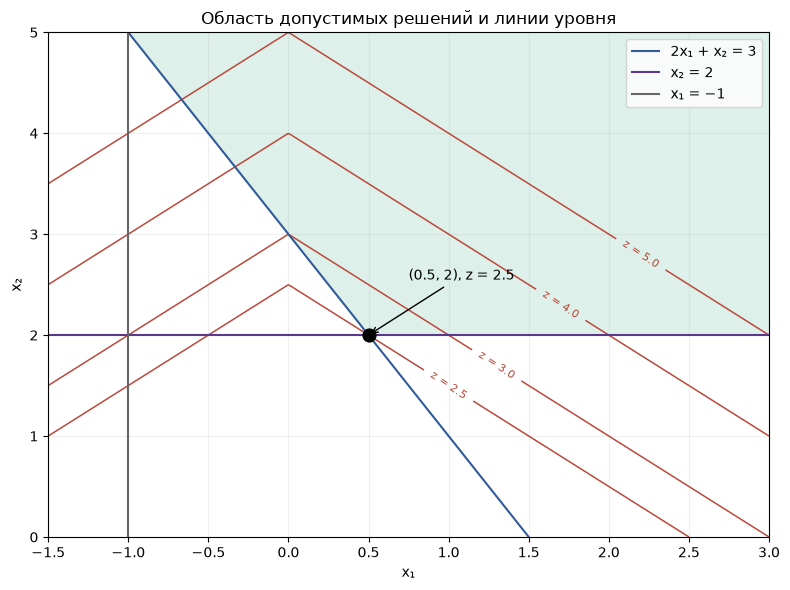

x₁ = 0.500, x₂ = 2.000, минимум = 2.500


In [10]:
xx = np.linspace(-1.5, 3.0, 500)
yy = np.linspace(0.0, 5.0, 500)
X, Y = np.meshgrid(xx, yy)
feasible = (2 * X + Y >= 3) & (X >= -1) & (Y >= 2)
levels = np.abs(X) + np.abs(Y)
fig, ax = plt.subplots(figsize=(8, 6))
ax.contourf(X, Y, feasible.astype(float), levels=[0.5, 1.5],
            colors=["#d9eee7"], alpha=0.85)
contours = ax.contour(X, Y, levels, levels=[2.5, 3, 4, 5],
                      colors="#ba4a3c", linewidths=1.1)
ax.clabel(contours, fmt="z = %.1f", fontsize=8,
          manual=[(1.0, 1.5), (1.3, 1.7), (1.7, 2.3), (2.2, 2.8)])
ax.plot(xx, 3 - 2 * xx, label="2x₁ + x₂ = 3", color="#315b9a")
ax.axhline(2, label="x₂ = 2", color="#5a388a")
ax.axvline(-1, label="x₁ = −1", color="#666666")
ax.scatter([0.5], [2], s=85, color="black", zorder=5)
ax.annotate("(0.5, 2), z = 2.5", (0.5, 2), xytext=(0.75, 2.55),
            arrowprops={"arrowstyle": "->"})
ax.set(xlim=(-1.5, 3), ylim=(0, 5), xlabel="x₁", ylabel="x₂",
       title="Область допустимых решений и линии уровня")
ax.legend(loc="upper right")
ax.grid(alpha=0.2)
plt.tight_layout()
plt.show()

m29 = pyo.ConcreteModel()
m29.i = pyo.RangeSet(1, 2)
m29.x = pyo.Var(m29.i, domain=pyo.Reals)
m29.u = pyo.Var(m29.i, domain=pyo.NonNegativeReals)
m29.v = pyo.Var(m29.i, domain=pyo.NonNegativeReals)
# Равенство связывает знак x_i с двумя неотрицательными частями.
m29.abs_balance = pyo.Constraint(m29.i,
    rule=lambda m, i: m.x[i] == m.u[i] - m.v[i])
m29.line = pyo.Constraint(expr=2 * m29.x[1] + m29.x[2] >= 3)
m29.x1_bound = pyo.Constraint(expr=m29.x[1] >= -1)
m29.x2_bound = pyo.Constraint(expr=m29.x[2] >= 2)
m29.norm = pyo.Objective(
    expr=sum(m29.u[i] + m29.v[i] for i in m29.i),
    sense=pyo.minimize,
)
solve(m29)
print(f"x₁ = {pyo.value(m29.x[1]):.3f}, x₂ = {pyo.value(m29.x[2]):.3f}, "
      f"минимум = {pyo.value(m29.norm):.3f}")

Минимальная линия уровня касается допустимой области в $(x_1,x_2)=(0{,}5;2)$; значение цели $2{,}5$. Линеаризация точна, потому что в задаче минимизации любая лишняя величина $u_i+v_i$ ухудшает цель. На оптимуме $u_1=0{,}5$, $u_2=2$, $v_1=v_2=0$.

## Задача 2.10. Дробно-линейная функция

**Условие.** Максимизировать $(5x_1+6x_2)/(2x_2+7)$ при $2x_1+3x_2\le6$, $2x_1+x_2\le3$, $x_1,x_2\ge0$. Знаменатель положителен на всей допустимой области.

**Математическая модель.** Преобразование Чарнеса—Купера: $t=(2x_2+7)^{-1}$, $y_i=tx_i$. Тогда $2y_2+7t=1$ и

$$\begin{aligned}
\max\;&5y_1+6y_2\\
2y_1+3y_2&\le6t,\\
2y_1+y_2&\le3t,\\
2y_2+7t&=1,\\
y_1,y_2,t&\ge0.
\end{aligned}$$

После решения исходные переменные восстанавливаются как $x_i=y_i/t$.

In [11]:
m210 = pyo.ConcreteModel()
m210.y1 = pyo.Var(domain=pyo.NonNegativeReals)
m210.y2 = pyo.Var(domain=pyo.NonNegativeReals)
m210.t = pyo.Var(domain=pyo.NonNegativeReals)
m210.objective = pyo.Objective(
    expr=5 * m210.y1 + 6 * m210.y2, sense=pyo.maximize)
m210.first = pyo.Constraint(expr=2 * m210.y1 + 3 * m210.y2 <= 6 * m210.t)
m210.second = pyo.Constraint(expr=2 * m210.y1 + m210.y2 <= 3 * m210.t)
# Нормировка устраняет знаменатель дробной цели.
m210.normalization = pyo.Constraint(expr=2 * m210.y2 + 7 * m210.t == 1)
solve(m210)
t = pyo.value(m210.t)
if t <= 0:
    raise RuntimeError("Неожиданное t=0: обратная замена невозможна")
x1, x2 = pyo.value(m210.y1) / t, pyo.value(m210.y2) / t
original_value = (5 * x1 + 6 * x2) / (2 * x2 + 7)
print(f"t = {t:.3f}, y₁ = {pyo.value(m210.y1):.3f}, "
      f"y₂ = {pyo.value(m210.y2):.3f}")
print(f"x₁ = {x1:.3f}, x₂ = {x2:.3f}; "
      f"максимум дроби = {original_value:.3f}")
print(f"Проверка: 2x₁+3x₂ = {2*x1+3*x2:.3f} ≤ 6, "
      f"2x₁+x₂ = {2*x1+x2:.3f} ≤ 3")

t = 0.100, y₁ = 0.075, y₂ = 0.150
x₁ = 0.750, x₂ = 1.500; максимум дроби = 1.275
Проверка: 2x₁+3x₂ = 6.000 ≤ 6, 2x₁+x₂ = 3.000 ≤ 3


$t=0{,}1$, $y_1=0{,}075$, $y_2=0{,}15$. Обратная замена даёт $(x_1,x_2)=(0{,}75;1{,}5)$; обе исходные границы активны. Максимальное значение дроби $12{,}75/10=1{,}275$.